# 05. Query-based detector: RT-DETR
RT-DETR-L (Ultralytics, COCO-pretrained): HGNetv2 backbone, hybrid encoder (attention only on the coarsest level),
transformer decoder with 300 object queries initialised from the top-scoring encoder features.
Training uses one-to-one Hungarian matching between queries and objects (+ 100 denoising queries),
so inference needs no NMS. Same frames, validation and budget (1.25 GPU-hours) as YOLO11.

In [ ]:
import os; os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
%load_ext autoreload
%autoreload 2
import sys, json, pickle, subprocess
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import PROC, ROOT, PROJECT, CHECKPOINTS, seed_everything, load_results, coco_evaluate
import yolo_utils as yu

seed_everything()
VAL_GT = PROC / "val_gt.json"
BUDGET_H = 1.25
RT_BASE_CFG = dict(model="rtdetr-l", queries=300, denoising=100, budget_h=BUDGET_H)

In [5]:
# batch 2 requested; Ultralytics lowers it automatically if it does not fit (the effective batch stays 64 via nbs)
w_base = yu.train_ultra("rtdetr_base", "rtdetr-l.pt", kind="rtdetr", imgsz=1280, batch=2, hours=BUDGET_H)
res_base, _ = yu.evaluate_ultra("rtdetr_base", w_base, VAL_GT, RT_BASE_CFG, kind="rtdetr", imgsz=1280)
display(pd.Series(res_base).to_frame().T)

Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosai

[W1107 17:15:34.286851888 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 39845888, total: 8082096128).
[W1107 17:15:34.292599203 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 41943040, total: 8082096128).


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5594.6±1791.0 MB/s, size: 483.7 KB)
train: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/train.cache... 2446 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2446/2446 570.0Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6063.2±1895.6 MB/s, size: 459.6 KB)
val: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/val.cache... 420 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 220.2Mit/s 0.0s
: 0% ──────────── 0/1223  0.8s

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      1/100       3.6G      2.804     0.9428      1.008         25       1280: 0% ──────────── 0/2446  0.6s

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
[W1107 17:15:35.307715477 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 2097152 bytes (free: 28180480, total: 8082096128).


      1/100       5.9G       1.09     0.5109     0.2495         58       1280: 100% ━━━━━━━━━━━━ 2446/2446 6.8it/s 5:580.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 10.7it/s 19.6s0.1s
                   all        420      20624      0.527      0.493      0.482      0.261

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/12      5.89G     0.7316      0.425     0.2649          9       1280: 0% ──────────── 1/2446 2.3it/s 0.3s<18:04

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (20 outputs left out)

      12/13      5.89G     0.5149     0.4299    0.05769          7       1280: 100% ━━━━━━━━━━━━ 2446/2446 7.6it/s 5:210.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.9it/s 17.7s0.2s
                   all        420      20624      0.615      0.509      0.514       0.28

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      13/13      5.88G     0.5065     0.4525    0.07051         96       1280: 0% ──────────── 1/2446 2.3it/s 0.3s<17:28

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      13/13      5.89G     0.5092     0.4275    0.05681         40       1280: 66% ━━━━━━━╸──── 1618/2446 8.3it/s 3:31<1:40
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.9it/s 17.7s0.2s
                   all        420      20624        0.6      0.532      0.516      0.281

13 epochs completed in 1.257 hours.
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_base/weights/last.pt, 66.5MB
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_base/weights/best.pt, 66.5MB

Validating /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_base/weights/best.pt...
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Imag

,name,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AP_person,AP_bicycle,AP_car,...,AP_bus,AP_motor,ms_per_image,epochs_done,train_hours,imgsz,model,queries,denoising,budget_h
0,rtdetr_base,0.2969,0.54,0.2876,0.1326,0.2681,0.4592,0.3061,0.2867,0.5473,...,0.2745,0.1236,68.0,13,1.26,1280,rtdetr-l,300,100,1.25


## Experiment 1: number of queries
Each query can output at most one object. Validation frames have up to 180 objects (median 42), and the metric
keeps up to 500 detections per image. 500 queries give more candidates in dense scenes at a higher decoder cost.

In [6]:
RT_NQ_CFG = {**RT_BASE_CFG, "queries": 500}
w_nq = yu.train_ultra("rtdetr_nq500", PROJECT / "configs" / "rtdetr-l-nq500.yaml", pretrained="rtdetr-l.pt",
                      kind="rtdetr", imgsz=1280, batch=2, hours=BUDGET_H)
res_nq, _ = yu.evaluate_ultra("rtdetr_nq500", w_nq, VAL_GT, RT_NQ_CFG, kind="rtdetr", imgsz=1280)

WARNING ⚠️ no model scale passed. Assuming scale='l'.
Transferred 926/941 items from pretrained weights
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.

[W1107 18:32:21.948815373 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 38600704, total: 8082096128).
[W1107 18:32:21.968601419 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 40697856, total: 8082096128).
[W1107 18:32:21.968715034 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 40697856, total: 8082096128).


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5729.8±2244.2 MB/s, size: 483.7 KB)
train: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/train.cache... 2446 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2446/2446 1.0Git/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6662.2±1938.4 MB/s, size: 459.6 KB)
val: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/val.cache... 420 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 220.2Mit/s 0.0s
: 0% ──────────── 0/1223  0.7s

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      1/100      6.61G      2.114      9.886     0.6781         12       1280: 0% ──────────── 1/2446 2.2it/s 0.5s<18:46

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      6.67G     0.8745      1.027     0.1586         58       1280: 100% ━━━━━━━━━━━━ 2446/2446 7.3it/s 5:340.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.4it/s 18.5s0.1s
                   all        420      20624      0.454      0.488      0.403      0.213

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/13         6G     0.5975     0.5704     0.2055          9       1280: 0% ──────────── 1/2446 2.4it/s 0.3s<17:13

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (19 outputs left out)

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      12/13         6G     0.5074     0.4424    0.05632          7       1280: 100% ━━━━━━━━━━━━ 2446/2446 7.5it/s 5:280.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.6it/s 18.1s0.1s
                   all        420      20624      0.568      0.505       0.49      0.263

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      13/13      5.98G     0.4912     0.4668     0.0708         96       1280: 0% ──────────── 1/2446 2.2it/s 0.3s<18:22

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      13/13         6G     0.4972     0.4381    0.05407         47       1280: 87% ━━━━━━━━━━── 2130/2446 7.7it/s 5:14<41.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 10.7it/s 19.7s0.1s
                   all        420      20624      0.551      0.505      0.477      0.258

13 epochs completed in 1.258 hours.
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nq500/weights/last.pt, 66.5MB
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nq500/weights/best.pt, 66.5MB

Validating /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nq500/weights/best.pt...
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
rtdetr-l-nq500 summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 109.3 GFLOPs
                 Class

## Experiment 2: no denoising queries
Hungarian matching can assign a query to different objects in consecutive iterations, which makes early training
unstable. Denoising (DN-DETR) adds noised copies of GT boxes as extra queries that must be reconstructed, a stable
auxiliary task. We switch it off (nd = 0) to measure its effect under a short budget.

In [7]:
RT_NODN_CFG = {**RT_BASE_CFG, "denoising": 0}
w_nodn = yu.train_ultra("rtdetr_nodn", PROJECT / "configs" / "rtdetr-l-nodn.yaml", pretrained="rtdetr-l.pt",
                        kind="rtdetr", imgsz=1280, batch=2, hours=BUDGET_H)
res_nodn, _ = yu.evaluate_ultra("rtdetr_nodn", w_nodn, VAL_GT, RT_NODN_CFG, kind="rtdetr", imgsz=1280)

WARNING ⚠️ no model scale passed. Assuming scale='l'.
Transferred 926/941 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.205 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

[W1107 19:49:29.457361999 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 22216704, total: 8082096128).
[W1107 19:49:29.471303353 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 36896768, total: 8082096128).
[W1107 19:49:29.471353076 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 36896768, total: 8082096128).


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4728.4±1822.7 MB/s, size: 483.7 KB)
train: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/train.cache... 2446 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2446/2446 1.1Git/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5814.9±1252.6 MB/s, size: 459.6 KB)
val: Scanning /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/data/proc/s10/labels/val.cache... 420 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 251.7Mit/s 0.0s
: 0% ──────────── 0/1223  0.8s

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      1/100      3.62G      1.704      2.682     0.4873         25       1280: 0% ──────────── 0/2446  0.4s

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
[W1107 19:49:29.308502852 CUDACachingAllocator.cpp:528] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 2097152 bytes (free: 23527424, total: 8082096128).


      1/100      5.82G     0.9949     0.7137     0.2042         58       1280: 100% ━━━━━━━━━━━━ 2446/2446 8.1it/s 5:040.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.3it/s 18.6s0.2s
                   all        420      20624      0.405      0.518      0.364      0.192

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/14      5.79G     0.6588     0.5406      0.238          9       1280: 0% ──────────── 1/2446 2.5it/s 0.2s<16:17

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (23 outputs left out)

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      14/15      5.82G     0.5365     0.4327    0.06238         53       1280: 100% ━━━━━━━━━━━━ 2446/2446 8.0it/s 5:050.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.3it/s 18.6s0.1s
                   all        420      20624       0.53      0.485      0.468      0.251

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      15/15       5.8G     0.3346      0.393    0.04334         20       1280: 0% ──────────── 1/2446 2.5it/s 0.2s<16:20

/home/julia/my_python_env/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      15/15      5.82G     0.5238     0.4269    0.05995         55       1280: 41% ━━━━╸─────── 1014/2446 8.8it/s 2:07<2:43
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 210/210 11.2it/s 18.8s0.2s
                   all        420      20624      0.552      0.482      0.471      0.257

15 epochs completed in 1.256 hours.
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nodn/weights/last.pt, 66.5MB
Optimizer stripped from /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nodn/weights/best.pt, 66.5MB

Validating /home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/runs/rtdetr_nodn/weights/best.pt...
Ultralytics 8.4.204 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7708MiB)
rtdetr-l-nodn summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image,epochs_done,batch
name,,,,,,,,,
yolo_base,0.2414,0.4676,0.2168,0.1333,0.2221,0.3894,26.8,26.0,4.0
rtdetr_base,0.2969,0.5400,0.2876,0.1326,0.2681,0.4592,68.0,13.0,NaN
rtdetr_nq500,0.2857,0.5280,0.2705,0.1223,0.2592,0.4498,75.3,13.0,NaN
rtdetr_nodn,0.2899,0.5371,0.2740,0.1361,0.2577,0.4530,73.1,15.0,NaN


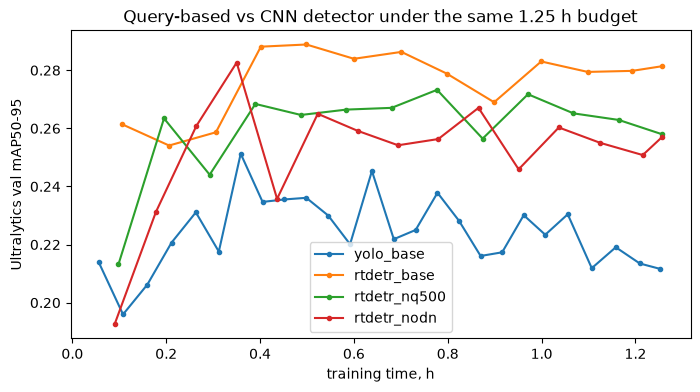

In [8]:
cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image", "epochs_done", "batch"]
names = ["yolo_base", "rtdetr_base", "rtdetr_nq500", "rtdetr_nodn"]
display(load_results().set_index("name").reindex(names)[[c for c in cols if c in load_results().columns]])

fig, ax = plt.subplots(figsize=(8, 4))
for n in names:
    h = yu.history(n); ax.plot(h["time"] / 3600, h["metrics/mAP50-95(B)"], marker=".", label=n)
ax.set_xlabel("training time, h"); ax.set_ylabel("Ultralytics val mAP50-95")
ax.set_title("Query-based vs CNN detector under the same 1.25 h budget"); ax.legend(); plt.show()

In [9]:
# mAP per validation clip vs scene density: are DETR queries a bottleneck in crowded clips?
gt = json.load(open(VAL_GT))
clip_of = {im["id"]: im["video"] for im in gt["images"]}
dens = pd.Series([clip_of[a["image_id"]] for a in gt["annotations"] if not a["iscrowd"]]).value_counts() \
       / pd.Series(clip_of).value_counts()
rows = []
for n in ["yolo_base", "rtdetr_base", "rtdetr_nq500"]:
    preds = pickle.load(open(CHECKPOINTS / f"{n}_val_preds.pkl", "rb"))
    for clip in dens.index:
        ids = [i for i, c in clip_of.items() if c == clip]
        rows.append({"model": n, "clip": clip, "objects/frame": round(dens[clip], 1),
                     "mAP": coco_evaluate(VAL_GT, preds, img_ids=ids)["mAP"]})
per_clip = pd.DataFrame(rows).pivot_table(index=["clip", "objects/frame"], columns="model", values="mAP")
display(per_clip.sort_index(level="objects/frame").round(3))

,model,rtdetr_base,rtdetr_nq500,yolo_base
clip,objects/frame,,,
uav0000268_05773_v,13.8,0.150,0.137,0.133
uav0000305_00000_v,34.8,0.331,0.340,0.160
uav0000339_00001_v,43.7,0.281,0.300,0.253
uav0000182_00000_v,48.5,0.238,0.208,0.192
uav0000117_02622_v,49.6,0.251,0.229,0.244
uav0000086_00000_v,49.8,0.276,0.268,0.220
uav0000137_00458_v,103.6,0.349,0.378,0.324


In [10]:
# Best model so far
import subprocess
from ultralytics import RTDETR
from common import write_submission
test_df = pd.read_csv(ROOT / "test_images.csv")
test_preds, _ = yu.predict_ultra(RTDETR(str(w_base)), yu.test_items(test_df), imgsz=1280)
sub_path = PROJECT / "submissions" / "rtdetr_base.csv"
write_submission(test_preds, test_df, sub_path)
subprocess.run(["kaggle", "competitions", "submit", "-c", "multiple-object-video-detection-hw-2-ucu-ai-2026",
                "-f", str(sub_path), "-m", f"RT-DETR-L 1280, val mAP {res_base['mAP']:.4f}"], check=True)

100%|██████████| 34.1M/34.1M [00:08<00:00, 4.31MB/s]


Submission ref: 58103722
3 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

CompletedProcess(args=['kaggle', 'competitions', 'submit', '-c', 'multiple-object-video-detection-hw-2-ucu-ai-2026', '-f', '/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/submissions/rtdetr_base.csv', '-m', 'RT-DETR-L 1280, val mAP 0.2969'], returncode=0)